In [3]:
from experiment_tracking.exp_tracker import fetch_experiment_results
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import anndata as ad
import shap
import gseapy as gp

/home/braemp4/.cache/pypoetry/virtualenvs/venetoclax-project-wl4ICAB4-py3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [53]:
results, ml_model, ft_eng_results = fetch_experiment_results('t11_14_gene_modules2026-09-03_11:35:15')

In [49]:
X_train_ad, X_test_ad = ft_eng_results[1], ft_eng_results[2]

In [6]:
gene_module_mappings= ft_eng_results[0]

In [7]:
gmmap = pd.DataFrame(gene_module_mappings.uns['gene_modles'])

In [8]:
gmmap

,gene,module
module_0,FRG2B,0
module_1,C1orf21,1
module_1,SYNM,1
module_1,EHD3,1
module_1,KCNH2,1
...,...,...
module_493,H3C11,493
module_493,C1orf141,493
module_493,RPE65,493
module_493,ODF1,493


In [9]:
X_train_ad.uns['gene_modules']

,module_0,module_1,module_2,module_3,module_5,module_6,module_7,module_8,module_10,module_11,...,module_478,module_479,module_480,module_481,module_485,module_488,module_490,module_492,module_493,module_498
RNA_SampleID,,,,,,,,,,,,,,,,,,,,,
SL414065,-9.965784,0.439160,-7.814069,5.195644,-3.457990,6.300387,-4.529196,0.317338,-1.012709,-5.155178,...,-6.506353,-0.619271,-9.965784,-9.965784,-2.480650,-1.086201,-9.965784,-9.965784,-6.825031,-9.965784
SL316611,-9.965784,0.748046,-5.114695,5.520905,-4.293359,5.908064,-1.423333,-0.654633,0.101690,-5.568851,...,-9.965784,-1.248108,-5.011588,-9.965784,2.750022,-3.171368,-9.965784,-5.573467,-7.039947,-6.506353
SL399348,-9.965784,0.452612,-3.548517,4.371094,-3.816037,4.743141,-1.619936,-2.284457,0.190707,-5.783095,...,-9.965784,-0.013043,-1.214240,-2.932361,-0.967713,-4.293359,-9.965784,-5.573467,-6.720054,-9.965784
SL242336,-9.965784,-0.566868,-5.795329,3.833893,-4.293359,4.328572,-3.893374,-1.922648,-1.591184,-5.473042,...,-7.000416,-3.171368,-1.831358,-9.965784,-0.628929,-1.639355,-5.573467,-9.965784,-6.071937,-9.965784
SL414057,-9.965784,0.631224,-4.992001,5.205812,-9.965784,3.981139,0.026508,-1.433068,0.923157,-5.517991,...,-8.236068,-3.171368,-9.965784,-9.965784,-0.246166,-2.727380,-9.965784,-4.608232,-5.060681,-6.506353
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SL432596,1.674009,0.563891,-3.610075,4.891732,-4.293359,4.924716,-0.164522,-2.010065,1.403026,-5.855770,...,-9.965784,-5.573467,2.403540,-5.573467,-5.768688,-2.388355,-5.573467,-3.457990,-5.426887,-9.965784
SL425882,-9.965784,0.150803,-6.089408,4.490618,-5.573467,5.228918,-1.298299,-1.367592,0.235582,-5.373112,...,-8.236068,-3.816037,-9.965784,-9.965784,1.346328,-1.994241,-9.965784,-9.965784,-5.560002,-9.965784
SL240795,-9.965784,0.661698,-2.604120,5.211606,-5.011588,4.393506,-1.184966,-2.661329,0.718277,-6.472849,...,-7.488686,-9.965784,-0.302226,-9.965784,-4.088979,-2.388355,-9.965784,-9.965784,-5.851228,-9.965784


In [ ]:
# I wonder if it would be equally useful to use single gene features highly correlated to t11;14

Background dataset has 111 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=111 when initializing the masker.


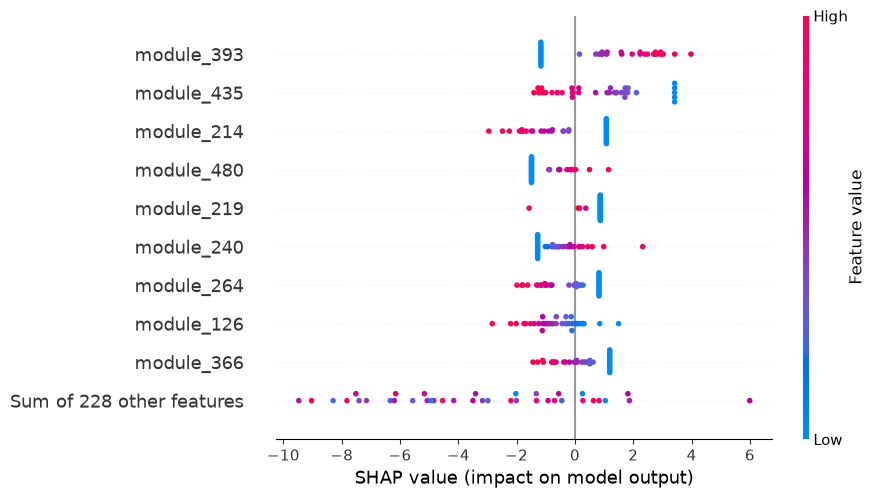

In [10]:
explainer = shap.LinearExplainer(ml_model, X_train_ad.uns['gene_modules'])
shap_values = explainer(X_test_ad.uns['gene_modules'])
shap.plots.beeswarm(shap_values)

In [15]:
gene_sets_dir = "../../data/GMT/"
# probably too many gene sets
#gene_sets = #['c2.all.v2026.1.Hs.symbols.gmt']
                            #'c6.all.v2026.1.Hs.symbols.gmt',
                            #'c7.all.v2026.1.Hs.symbols.gmt',
                            #'c8.all.v2026.1.Hs.symbols.gmt',
                            #'h.all.v2026.1.Hs.symbols.gmt'
                            #]
gene_sets = ['h.all.v2026.1.Hs.symbols.gmt']
gene_sets = [gene_sets_dir + gs for gs in gene_sets]


In [31]:
res = {}
#top_modules = [393,435,214,480,219,240,264, 126,366]
#top_modules = [393,435]

for i in range(500):
    genes = list(gmmap[gmmap["module"] == i]['gene'])

    if len(genes) > 0:
        print(gene_sets)
        enr = gp.enrich(
            gene_list=genes,
            gene_sets=gene_sets,
            background=None,
            outdir=None,
            verbose=True,
        )
    res[i] = enr.results
    


2026-09-03 16:21:28,715 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:28,719 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:28,725 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:28,729 [ERROR] No hits returned for all input gene sets!
2026-09-03 16:21:28,733 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:28,736 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:28,741 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:28,759 [INFO] Done.
2026-09-03 16:21:28,763 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:28,765 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:28,771 [INFO]   Backgro

['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']


2026-09-03 16:21:28,923 [INFO] Done.
2026-09-03 16:21:28,927 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:28,930 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:28,938 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:28,955 [INFO] Done.
2026-09-03 16:21:28,959 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:28,961 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:28,966 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:28,971 [INFO] Done.
2026-09-03 16:21:28,981 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:28,983 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:28,989 [INFO]   Backgro

['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']


2026-09-03 16:21:29,136 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:29,139 [ERROR] No hits returned for all input gene sets!
2026-09-03 16:21:29,143 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:29,145 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:29,149 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:29,156 [INFO] Done.
2026-09-03 16:21:29,160 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:29,164 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:29,170 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:29,174 [INFO] Done.
2026-09-03 16:21:29,180 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gm

...

['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']


2026-09-03 16:21:32,832 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:32,839 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:32,844 [INFO] Done.
2026-09-03 16:21:32,849 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:32,852 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:32,857 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:32,860 [ERROR] No hits returned for all input gene sets!
2026-09-03 16:21:32,870 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:32,872 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:32,879 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:32,882 [ERROR] No hits 

['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']


2026-09-03 16:21:33,059 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:33,063 [ERROR] No hits returned for all input gene sets!
2026-09-03 16:21:33,071 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:33,074 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:33,076 [INFO]   Genes in GMT file are all in upper case, convert query to upper case.
2026-09-03 16:21:33,086 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:33,095 [INFO] Done.
2026-09-03 16:21:33,107 [INFO] User defined gene sets is given: ../../data/GMT/h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:33,110 [INFO] Off-line enrichment analysis with library: h.all.v2026.1.Hs.symbols.gmt
2026-09-03 16:21:33,117 [INFO]   Background is not set! Use all 4384 genes in h.all.v2026.1.Hs.symbols.gmt.
2026-09-03 16:21:33,121 [ERROR] No hits 

['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']
['../../data/GMT/h.all.v2026.1.Hs.symbols.gmt']


In [39]:
res[3] # enrichr can lead us in the right direction but we must consider  pval < 0.05



,Gene_set,Term,Overlap,P-value,Adjusted P-value,Odds Ratio,Combined Score,Genes
0,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_ALLOGRAFT_REJECTION,1/200,4.293886e-01,0.429389,2.728669,2.306798,IL2RG
1,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_ANDROGEN_RESPONSE,1/101,2.442539e-01,0.359076,5.545101,7.816079,SAT1
2,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_APICAL_SURFACE,1/44,1.141426e-01,0.228285,12.982009,28.174939,IL2RG
3,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_APOPTOSIS,4/161,6.886705e-04,0.006887,14.169748,103.166359,SAT1;ATF3;BIRC3;LMNA
4,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_CHOLESTEROL_HOMEOSTASIS,1/74,1.849800e-01,0.336327,7.629991,12.875666,ATF3
5,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_COMPLEMENT,1/200,4.293886e-01,0.429389,2.728669,2.306798,TNFAIP3
6,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_DNA_REPAIR,1/150,3.418397e-01,0.427300,3.684892,3.955411,PDE4B
7,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,2/200,1.012152e-01,0.224923,5.007197,11.469016,SAT1;TNFAIP3
8,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_HYPOXIA,2/200,1.012152e-01,0.224923,5.007197,11.469016,ATF3;TNFAIP3
9,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_IL2_STAT5_SIGNALING,1/199,4.277477e-01,0.429389,2.743073,2.329477,NFKBIZ


In [111]:
from sklearn.inspection import permutation_importance
from feature_selection.top_ft_anova_from_sens import binarize_labels
from gseapy import dotplot, barplot


In [54]:
ft_imp = permutation_importance(ml_model, X_test_ad.uns['gene_modules'],binarize_labels(X_test_ad.obs["ABT-199"]))

In [79]:
ft_imp_df = pd.DataFrame(ft_imp["importances_mean"], X_test_ad.uns['gene_modules'].columns, columns=["Importance"]).sort_values(by="Importance", ascending=False)
ft_imp_df.head(12)


#ft_imp_df = ft_imp_df.sort_values()

,Importance
module_393,0.073684
module_435,0.068421
module_450,0.063158
module_316,0.052632
module_438,0.042105
module_292,0.042105
module_240,0.036842
module_320,0.036842
module_126,0.036842
module_375,0.036842


In [116]:
for key in ft_imp_df.index:
    key = int(key.replace('module_',""))

    res[key]
    if not isinstance(res[key], list):
        print(res[key])

                       Gene_set                              Term Overlap  \
0  h.all.v2026.1.Hs.symbols.gmt  HALLMARK_ESTROGEN_RESPONSE_EARLY   1/200   

   P-value  Adjusted P-value  Odds Ratio  Combined Score   Genes  
0  0.04562           0.04562   62.924812      194.274031  KCNK15  
                       Gene_set                     Term Overlap  P-value  \
0  h.all.v2026.1.Hs.symbols.gmt  HALLMARK_MYC_TARGETS_V1   1/200  0.04562   

   Adjusted P-value  Odds Ratio  Combined Score Genes  
0           0.04562   62.924812      194.274031  UBA2  
                       Gene_set                        Term Overlap   P-value  \
0  h.all.v2026.1.Hs.symbols.gmt  HALLMARK_KRAS_SIGNALING_UP   1/200  0.045620   
1  h.all.v2026.1.Hs.symbols.gmt    HALLMARK_SPERMATOGENESIS   1/135  0.030794   

   Adjusted P-value  Odds Ratio  Combined Score Genes  
0           0.04562   62.924812      194.274031  SCG5  
1           0.04562   94.784387      329.891565  SCG5  
                       Gene_set 